[slope_1] step=5000/20000 elapsed=6.0s spd=833.1 steps/s eta=00m18s
[slope_1] step=10000/20000 elapsed=13.9s spd=719.8 steps/s eta=00m14s
[slope_1] step=10000/20000 elapsed=13.9s spd=719.8 steps/s eta=00m14s
[slope_1] step=15000/20000 elapsed=23.8s spd=630.7 steps/s eta=00m08s
[slope_1] step=15000/20000 elapsed=23.8s spd=630.7 steps/s eta=00m08s
[slope_1] step=20000/20000 elapsed=35.2s spd=567.9 steps/s eta=00m00s
[slope_1] step=20000/20000 elapsed=35.2s spd=567.9 steps/s eta=00m00s
[slope_2] step=5000/20000 elapsed=6.0s spd=833.3 steps/s eta=00m18s
[slope_2] step=5000/20000 elapsed=6.0s spd=833.3 steps/s eta=00m18s
[slope_2] step=10000/20000 elapsed=14.0s spd=716.1 steps/s eta=00m14s
[slope_2] step=10000/20000 elapsed=14.0s spd=716.1 steps/s eta=00m14s
[slope_2] step=15000/20000 elapsed=23.6s spd=634.6 steps/s eta=00m08s
[slope_2] step=15000/20000 elapsed=23.6s spd=634.6 steps/s eta=00m08s
[slope_2] step=20000/20000 elapsed=35.1s spd=570.5 steps/s eta=00m00s
[slope_2] step=20000/20000

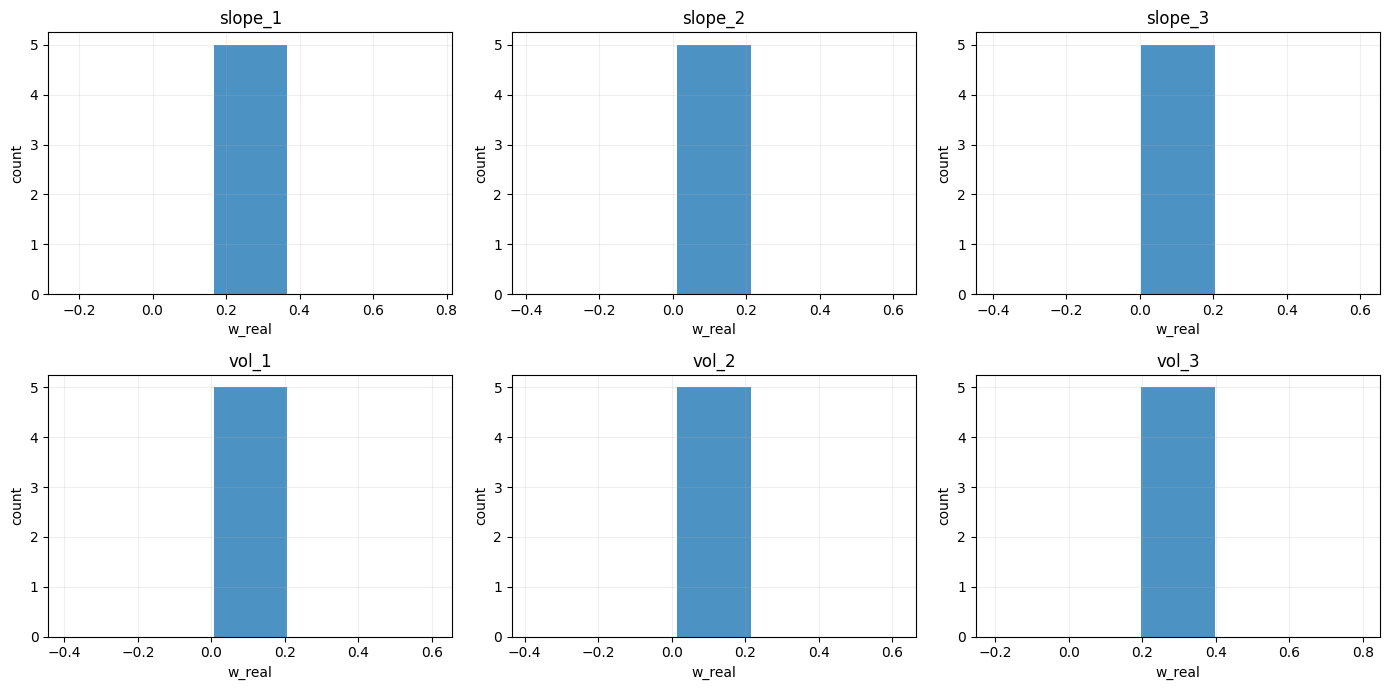

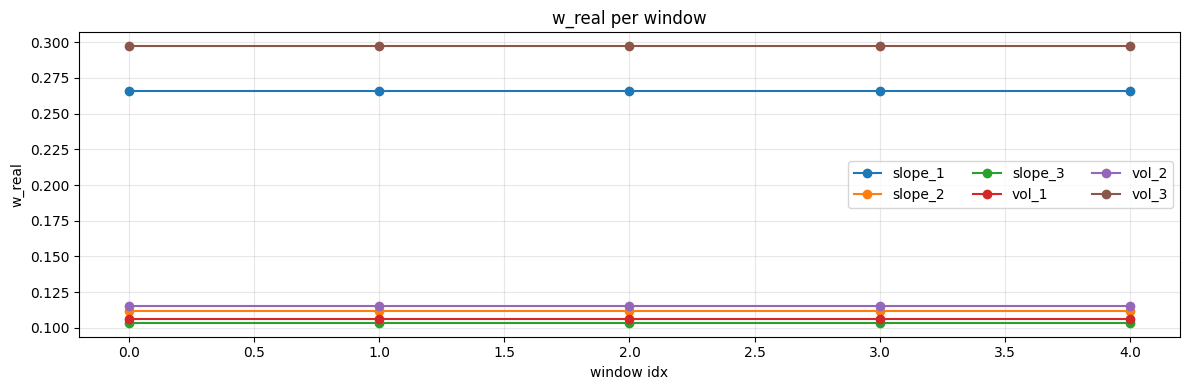

In [4]:
import os
import time
import numpy as np
import torch

# 让notebook能 import MacroHFT
import sys
# 需要把“包含 MacroHFT/ 目录的父目录”加入 sys.path
# 你当前工程结构为 /home/ustc1958/lxy/129/MacroHFT/MacroHFT/...
MACROHFT_PROJECT = "/home/ustc1958/lxy/129/MacroHFT"
if MACROHFT_PROJECT not in sys.path:
    sys.path.insert(0, MACROHFT_PROJECT)

try:
    # 情况 A：包名为 MacroHFT（/path/MacroHFT/MacroHFT/...）
    from MacroHFT.model.net import subagent
    from MacroHFT.env.high_level_env import Testing_Env
except ModuleNotFoundError:
    # 情况 B：在某些运行目录下，直接以项目内相对包导入
    from model.net import subagent
    from env.high_level_env import Testing_Env


def softmax_np(x, t=1.0):
    x = np.asarray(x, dtype=np.float64)
    x = x / float(t)
    x = x - np.max(x)
    e = np.exp(x)
    return e / (np.sum(e) + 1e-12)


def _format_eta(seconds: float) -> str:
    seconds = float(max(seconds, 0.0))
    m, s = divmod(int(seconds + 0.5), 60)
    h, m = divmod(m, 60)
    if h > 0:
        return f"{h}h{m:02d}m{s:02d}s"
    return f"{m:02d}m{s:02d}s"


@torch.no_grad()
def run_one_agent(env, agent, device, max_steps=None, progress_every=5000, desc=""):
    s, s2, s3, info = env.reset()
    done = False
    actions = []
    rewards = []

    step = 0
    t0 = time.time()

    while not done:
        x1 = torch.FloatTensor(s).to(device)
        x2 = torch.FloatTensor(s2).to(device)
        prev_a = torch.tensor([info["previous_action"]], dtype=torch.long, device=device)

        q = agent(x1, x2, prev_a)  # [1,2]
        a = int(torch.argmax(q, dim=1).item())

        s, s2, s3, r, done, info = env.step(a)
        actions.append(a)
        rewards.append(r)
        step += 1

        if progress_every and step % int(progress_every) == 0:
            elapsed = time.time() - t0
            spd = step / max(elapsed, 1e-9)
            if max_steps is not None and max_steps > 0:
                eta = (max_steps - step) / max(spd, 1e-9)
                print(f"[{desc}] step={step}/{max_steps} elapsed={elapsed:.1f}s spd={spd:.1f} steps/s eta={_format_eta(eta)}", flush=True)
            else:
                print(f"[{desc}] step={step} elapsed={elapsed:.1f}s spd={spd:.1f} steps/s", flush=True)

        if max_steps is not None and step >= int(max_steps):
            # 提前截断：做 sanity check / 估算速度
            break

    # 真实环境返回
    portfit_magine, final_balance, required_money, commission_fee = env.get_final_return_rate(slient=True)
    ret = final_balance / required_money
    return {
        "return_rate": float(ret),
        "final_balance": float(final_balance),
        "required_money": float(required_money),
        "commission_fee": float(commission_fee),
        "action_0_frac": float(np.mean(np.array(actions) == 0)) if len(actions) else 0.0,
        "action_1_frac": float(np.mean(np.array(actions) == 1)) if len(actions) else 0.0,
        "reward_sum": float(np.sum(rewards)),
        "steps": int(len(actions)),
        "elapsed_sec": float(time.time() - t0),
    }


def build_env(data_feather, tech_indicator_list, tech_indicator_list_trend, clf_list,
              transcation_cost, back_time_length, max_holding_number):
    import pandas as pd
    df = pd.read_feather(data_feather)
    env = Testing_Env(
        df=df,
        tech_indicator_list=tech_indicator_list,
        tech_indicator_list_trend=tech_indicator_list_trend,
        clf_list=clf_list,
        transcation_cost=transcation_cost,
        back_time_length=back_time_length,
        max_holding_number=max_holding_number,
        initial_action=0,
    )
    return env


# =========================
# 配置区：你只需要改这里
# =========================
DATA_ROOT = "/home/ustc1958/lxy/129/MacroHFT/data"   # 你刚刚给的 129/MacroHFT/data
DATASET = "ETHUSDT"
SPLIT = "val"  # val / test
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

TRANSCATION_COST = 0.2 / 1000
BACK_TIME_LENGTH = 1
MAX_HOLDING_NUMBER = 0.2  # ETH=0.2

# 先做 sanity check：只跑前 N 步（设为 None 表示全量跑完）
MAX_STEPS = 20000
PROGRESS_EVERY = 5000

# 六个 agent 权重路径（按顺序：slope1 slope2 slope3 vol1 vol2 vol3）
# 默认指向 131testbest_model（你当前的“低层六个子代理”目录）
AGENT_PATHS = [
    "/home/ustc1958/lxy/129/MacroHFT/result/low_level/ETHUSDT/131testbest_model/slope/1/best_model.pkl",
    "/home/ustc1958/lxy/129/MacroHFT/result/low_level/ETHUSDT/131testbest_model/slope/2/best_model.pkl",
    "/home/ustc1958/lxy/129/MacroHFT/result/low_level/ETHUSDT/131testbest_model/slope/3/best_model.pkl",
    "/home/ustc1958/lxy/129/MacroHFT/result/low_level/ETHUSDT/131testbest_model/vol/1/best_model.pkl",
    "/home/ustc1958/lxy/129/MacroHFT/result/low_level/ETHUSDT/131testbest_model/vol/2/best_model.pkl",
    "/home/ustc1958/lxy/129/MacroHFT/result/low_level/ETHUSDT/131testbest_model/vol/3/best_model.pkl",
]

WEIGHT_MODE = "softmax"       # softmax / positive_clip
SOFTMAX_TEMP = 1.0

# =========================
# 主逻辑
# =========================
tech_indicator_list = np.load(os.path.join(DATA_ROOT, "feature_list", "single_features.npy"), allow_pickle=True).tolist()
techn_indicator_list_trend_path = os.path.join(DATA_ROOT, "feature_list", "trend_features.npy")
tech_indicator_list_trend = np.load(techn_indicator_list_trend_path, allow_pickle=True).tolist()

clf_list = ["slope_360", "vol_360"]

n_state_1 = len(tech_indicator_list)
n_state_2 = len(tech_indicator_list_trend)
n_action = 2
hidden = 64

names = ["slope_1", "slope_2", "slope_3", "vol_1", "vol_2", "vol_3"]

data_feather = os.path.join(DATA_ROOT, DATASET, "whole", f"{SPLIT}.feather")
if not os.path.exists(data_feather):
    raise FileNotFoundError(f"data file not found: {data_feather}")

# 校验 6 个路径
if len(AGENT_PATHS) != 6:
    raise ValueError("AGENT_PATHS 必须是长度为 6 的列表：slope1 slope2 slope3 vol1 vol2 vol3")
for i, p in enumerate(AGENT_PATHS):
    if not p:
        raise ValueError(f"AGENT_PATHS[{i}] 为空，请补全 6 个权重路径")
    if not os.path.exists(p):
        raise FileNotFoundError(f"agent weight not found: {p}")

# 每个 agent 用独立 env，避免状态污染

def make_env():
    return build_env(
        data_feather=data_feather,
        tech_indicator_list=tech_indicator_list,
        tech_indicator_list_trend=tech_indicator_list_trend,
        clf_list=clf_list,
        transcation_cost=TRANSCATION_COST,
        back_time_length=BACK_TIME_LENGTH,
        max_holding_number=MAX_HOLDING_NUMBER,
    )

results = []
for name, path in zip(names, AGENT_PATHS):
    agent = subagent(n_state_1, n_state_2, n_action, hidden).to(DEVICE)
    agent.load_state_dict(torch.load(path, map_location=DEVICE))
    agent.eval()

    env = make_env()
    res = run_one_agent(env, agent, DEVICE, max_steps=MAX_STEPS, progress_every=PROGRESS_EVERY, desc=name)
    res["name"] = name
    res["path"] = path
    results.append(res)

rr = np.array([r["return_rate"] for r in results], dtype=np.float64)

if WEIGHT_MODE == "softmax":
    w = softmax_np(rr, t=SOFTMAX_TEMP)
elif WEIGHT_MODE == "positive_clip":
    base = np.median(rr)
    s = np.maximum(rr - base, 0.0)
    w = (s / s.sum()) if s.sum() > 1e-12 else (np.ones_like(s) / len(s))
else:
    raise ValueError(f"unknown WEIGHT_MODE: {WEIGHT_MODE}")

print("=" * 100)
print(f"[real-env-eval] dataset={DATASET} split={SPLIT} weight_mode={WEIGHT_MODE} device={DEVICE}")
print(f"[run] MAX_STEPS={MAX_STEPS} PROGRESS_EVERY={PROGRESS_EVERY}")
print("=" * 100)
for i, r in enumerate(results):
    steps = r.get("steps", 0)
    elapsed = r.get("elapsed_sec", float('nan'))
    spd = (steps / elapsed) if (elapsed and elapsed > 0) else float('nan')
    print(
        f"{i:02d} {r['name']:7s} "
        f"return_rate={r['return_rate']:.6f} "
        f"final={r['final_balance']:.2f} req={r['required_money']:.2f} fee={r['commission_fee']:.2f} "
        f"act0={r['action_0_frac']:.3f} act1={r['action_1_frac']:.3f} "
        f"steps={steps} spd={spd:.1f}/s "
        f"w_real={w[i]:.4f}\n"
        f"    path={r['path']}"
    )

print("-" * 100)
print("w_real (normalized):")
print(dict(zip(names, [float(x) for x in w])))

# =========================
# 扩展逻辑：滑窗多段回测
# =========================
# 经验权重的“分布”评估：滑窗多段回测
# - WINDOW_STEPS: 每段跑多少步
# - N_WINDOWS: 跑多少段（总耗时 ~ N_WINDOWS * 6 * WINDOW_STEPS / steps_per_sec）
# 说明：Testing_Env.reset() 默认从序列起点开始；这里用“不同 initial_action + 不同随机 seed”做近似分段抽样。
# 如果你希望严格的时间分段（从不同时间点开始），需要改 env 支持 start_index。
WINDOW_STEPS = 20000
N_WINDOWS = 5
PROGRESS_EVERY = 5000

# 六个 agent 权重路径（按顺序：slope1 slope2 slope3 vol1 vol2 vol3）
AGENT_PATHS = [
    "/home/ustc1958/lxy/129/MacroHFT/result/low_level/ETHUSDT/131testbest_model/slope/1/best_model.pkl",
    "/home/ustc1958/lxy/129/MacroHFT/result/low_level/ETHUSDT/131testbest_model/slope/2/best_model.pkl",
    "/home/ustc1958/lxy/129/MacroHFT/result/low_level/ETHUSDT/131testbest_model/slope/3/best_model.pkl",
    "/home/ustc1958/lxy/129/MacroHFT/result/low_level/ETHUSDT/131testbest_model/vol/1/best_model.pkl",
    "/home/ustc1958/lxy/129/MacroHFT/result/low_level/ETHUSDT/131testbest_model/vol/2/best_model.pkl",
    "/home/ustc1958/lxy/129/MacroHFT/result/low_level/ETHUSDT/131testbest_model/vol/3/best_model.pkl",
]

WEIGHT_MODE = "softmax"       # softmax / positive_clip
SOFTMAX_TEMP = 1.0

# =========================
# 主逻辑
# =========================
tech_indicator_list = np.load(os.path.join(DATA_ROOT, "feature_list", "single_features.npy"), allow_pickle=True).tolist()
techn_indicator_list_trend_path = os.path.join(DATA_ROOT, "feature_list", "trend_features.npy")
tech_indicator_list_trend = np.load(techn_indicator_list_trend_path, allow_pickle=True).tolist()

clf_list = ["slope_360", "vol_360"]

n_state_1 = len(tech_indicator_list)
n_state_2 = len(tech_indicator_list_trend)
n_action = 2
hidden = 64

names = ["slope_1", "slope_2", "slope_3", "vol_1", "vol_2", "vol_3"]

data_feather = os.path.join(DATA_ROOT, DATASET, "whole", f"{SPLIT}.feather")
if not os.path.exists(data_feather):
    raise FileNotFoundError(f"data file not found: {data_feather}")

# 校验 6 个路径
if len(AGENT_PATHS) != 6:
    raise ValueError("AGENT_PATHS 必须是长度为 6 的列表：slope1 slope2 slope3 vol1 vol2 vol3")
for i, p in enumerate(AGENT_PATHS):
    if not p:
        raise ValueError(f"AGENT_PATHS[{i}] 为空，请补全 6 个权重路径")
    if not os.path.exists(p):
        raise FileNotFoundError(f"agent weight not found: {p}")

# 延迟 import（只在画图时用，避免环境没装也能跑核心逻辑）
try:
    import matplotlib.pyplot as plt
except Exception:
    plt = None


def make_env():
    # 每个 agent 用独立 env，避免状态污染
    return build_env(
        data_feather=data_feather,
        tech_indicator_list=tech_indicator_list,
        tech_indicator_list_trend=tech_indicator_list_trend,
        clf_list=clf_list,
        transcation_cost=TRANSCATION_COST,
        back_time_length=BACK_TIME_LENGTH,
        max_holding_number=MAX_HOLDING_NUMBER,
    )


def compute_w_from_results(results):
    rr = np.array([r["return_rate"] for r in results], dtype=np.float64)
    if WEIGHT_MODE == "softmax":
        w = softmax_np(rr, t=SOFTMAX_TEMP)
    elif WEIGHT_MODE == "positive_clip":
        base = np.median(rr)
        s = np.maximum(rr - base, 0.0)
        w = (s / s.sum()) if s.sum() > 1e-12 else (np.ones_like(s) / len(s))
    else:
        raise ValueError(f"unknown WEIGHT_MODE: {WEIGHT_MODE}")
    return w, rr


# 预加载 6 个 agent（避免每个窗口重复 load 权重）
agents = []
for name, path in zip(names, AGENT_PATHS):
    agent = subagent(n_state_1, n_state_2, n_action, hidden).to(DEVICE)
    agent.load_state_dict(torch.load(path, map_location=DEVICE))
    agent.eval()
    agents.append(agent)

# 逐窗口评估：收集每段的 w_real
W = []      # [n_windows, 6]
RR = []     # [n_windows, 6]
META = []   # 每段耗时等信息

print("=" * 100)
print(f"[real-env-eval windows] dataset={DATASET} split={SPLIT} weight_mode={WEIGHT_MODE} device={DEVICE}")
print(f"[cfg] WINDOW_STEPS={WINDOW_STEPS} N_WINDOWS={N_WINDOWS} PROGRESS_EVERY={PROGRESS_EVERY} SOFTMAX_TEMP={SOFTMAX_TEMP}")
print("=" * 100)

for wi in range(int(N_WINDOWS)):
    # 用不同随机种子影响 env.reset 的 initial_action 等随机分支（如果 env 内部有随机逻辑）
    # 注意：这不是严格的“不同时间段起点”，更像不同随机初始化的重复试验。
    np.random.seed(12345 + wi)
    torch.manual_seed(12345 + wi)

    window_results = []
    t_win0 = time.time()

    for name, agent in zip(names, agents):
        env = make_env()
        res = run_one_agent(env, agent, DEVICE, max_steps=WINDOW_STEPS, progress_every=PROGRESS_EVERY, desc=f"w{wi}-{name}")
        res["name"] = name
        window_results.append(res)

    w, rr = compute_w_from_results(window_results)
    W.append(w)
    RR.append(rr)
    META.append({"window": wi, "elapsed_sec": time.time() - t_win0})

    print("-" * 100)
    print(f"[window {wi}] elapsed={META[-1]['elapsed_sec']:.1f}s")
    print("w_real:", dict(zip(names, [float(x) for x in w])))

W = np.asarray(W, dtype=np.float64)
RR = np.asarray(RR, dtype=np.float64)

# ==========
# 分布统计
# ==========
print("=" * 100)
print("[w_real distribution across windows]")
print(f"shape: W={W.shape} (n_windows,6)")
print("=" * 100)

qs = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]
for j, name in enumerate(names):
    x = W[:, j]
    qv = np.quantile(x, qs)
    print(
        f"{name:7s} mean={x.mean():.4f} std={x.std(ddof=0):.4f} "
        + " ".join([f"q{int(q*100):02d}={v:.4f}" for q, v in zip(qs, qv)])
    )

# top1 频率（窗口级）：哪个 agent 在该窗口里 w_real 最大
win_top1 = W.argmax(axis=1)
uniq, cnt = np.unique(win_top1, return_counts=True)
print("-" * 100)
print("top1 frequency across windows:")
print({names[int(k)]: int(v) for k, v in zip(uniq, cnt)})

# ==========
# 可视化（如果 matplotlib 可用）
# ==========
if plt is not None:
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    axes = axes.ravel()
    for j, name in enumerate(names):
        ax = axes[j]
        ax.hist(W[:, j], bins=min(10, max(3, int(N_WINDOWS))), alpha=0.8)
        ax.set_title(name)
        ax.set_xlabel("w_real")
        ax.set_ylabel("count")
        ax.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

    # 窗口序列曲线
    plt.figure(figsize=(12, 4))
    for j, name in enumerate(names):
        plt.plot(W[:, j], marker='o', label=name)
    plt.title("w_real per window")
    plt.xlabel("window idx")
    plt.ylabel("w_real")
    plt.grid(True, alpha=0.3)
    plt.legend(ncol=3)
    plt.tight_layout()
    plt.show()
else:
    print("[warn] matplotlib 不可用，跳过直方图/曲线图。")